In [214]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline 
import warnings

warnings.filterwarnings('ignore')

In [215]:
train = pd.read_csv("D:\ML smart loan prediction\loan_sanction_train.csv",engine="python",on_bad_lines="skip")
test = pd.read_csv("D:\ML smart loan prediction\loan_sanction_test.csv",engine="python",on_bad_lines="skip")

In [216]:
train.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [217]:
test.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area
0,LP001015,Male,Yes,0,Graduate,No,5720,0,110.0,360.0,1.0,Urban
1,LP001022,Male,Yes,1,Graduate,No,3076,1500,126.0,360.0,1.0,Urban
2,LP001031,Male,Yes,2,Graduate,No,5000,1800,208.0,360.0,1.0,Urban
3,LP001035,Male,Yes,2,Graduate,No,2340,2546,100.0,360.0,NaN,Urban
4,LP001051,Male,No,0,Not Graduate,No,3276,0,78.0,360.0,1.0,Urban


In [218]:
train.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


In [219]:
test.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,367.000000,367.000000,362.000000,361.000000,338.000000
mean,4805.599455,1569.577657,136.132597,342.537396,0.825444
std,4910.685399,2334.232099,61.366652,65.156643,0.380150
min,0.000000,0.000000,28.000000,6.000000,0.000000
25%,2864.000000,0.000000,100.250000,360.000000,1.000000
50%,3786.000000,1025.000000,125.000000,360.000000,1.000000
75%,5060.000000,2430.500000,158.000000,360.000000,1.000000
max,72529.000000,24000.000000,550.000000,480.000000,1.000000


In [220]:
# it is safe to store original data before performing any actions
train_original = train.copy()
test_original = test.copy()

In [221]:
train.columns

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status'],
      dtype='str')

In [222]:
test.columns

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area'],
      dtype='str')

In [223]:
# while perfoeming the eda and all if we notice any requirement for changing datatype we have to do it
train.dtypes

Loan_ID                  str
Gender                   str
Married                  str
Dependents               str
Education                str
Self_Employed            str
ApplicantIncome        int64
CoapplicantIncome    float64
LoanAmount           float64
Loan_Amount_Term     float64
Credit_History       float64
Property_Area            str
Loan_Status              str
dtype: object

In [224]:
train.shape, test.shape

((614, 13), (367, 12))

In [225]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    str    
 1   Gender             601 non-null    str    
 2   Married            611 non-null    str    
 3   Dependents         599 non-null    str    
 4   Education          614 non-null    str    
 5   Self_Employed      582 non-null    str    
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    str    
 12  Loan_Status        614 non-null    str    
dtypes: float64(4), int64(1), str(8)
memory usage: 62.5 KB


# EDA

In [226]:
# we have to start with the target variable start analizing the target variable and normalize it.
train["Loan_Status"].value_counts()

Loan_Status
Y    422
N    192
Name: count, dtype: int64

In [227]:
train["Loan_Status"].value_counts(normalize=True)

Loan_Status
Y    0.687296
N    0.312704
Name: proportion, dtype: float64

<Axes: xlabel='Loan_Status'>

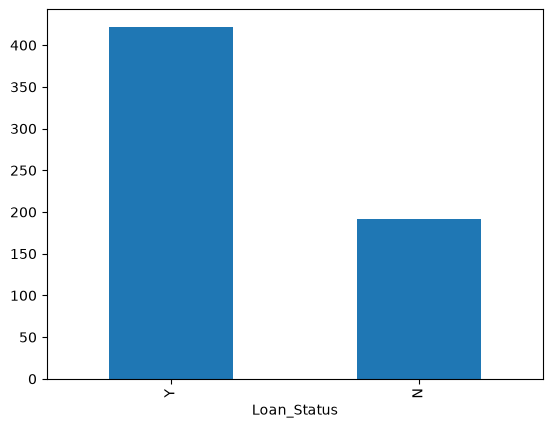

In [228]:
train["Loan_Status"].value_counts().plot.bar()

Now lets visualize each variable separately.

1. Categorical features These features have categories ( Gender, Married, Self_Employed, Credit_History, Loan_Status )

2. Ordinal features: Variables in categorical features having some order involved ( Dependents , Education, Property_Area)

3. Numerical features These features have numerical values ( ApplicantIncome , CoapplicantIncome, LoanAmount , Loan_Amount_Term)

Lets visualize the categorical and ordinal features first.

Categorical features

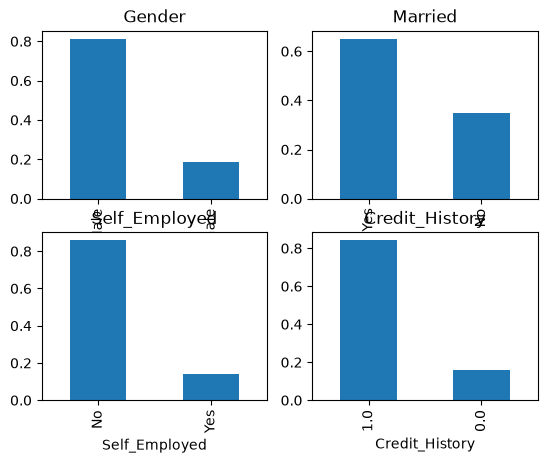

In [229]:
plt.figure(1)
plt.subplot(221) # (rows,col,plot_num)
train['Gender'].value_counts(normalize=True).plot.bar(title="Gender")
plt.subplot(222)
train['Married'].value_counts(normalize=True).plot.bar(title="Married")
plt.subplot(223)
train['Self_Employed'].value_counts(normalize=True).plot.bar(title="Self_Employed")
plt.subplot(224)
train['Credit_History'].value_counts(normalize=True).plot.bar(title="Credit_History")
plt.show()


Ordinal features

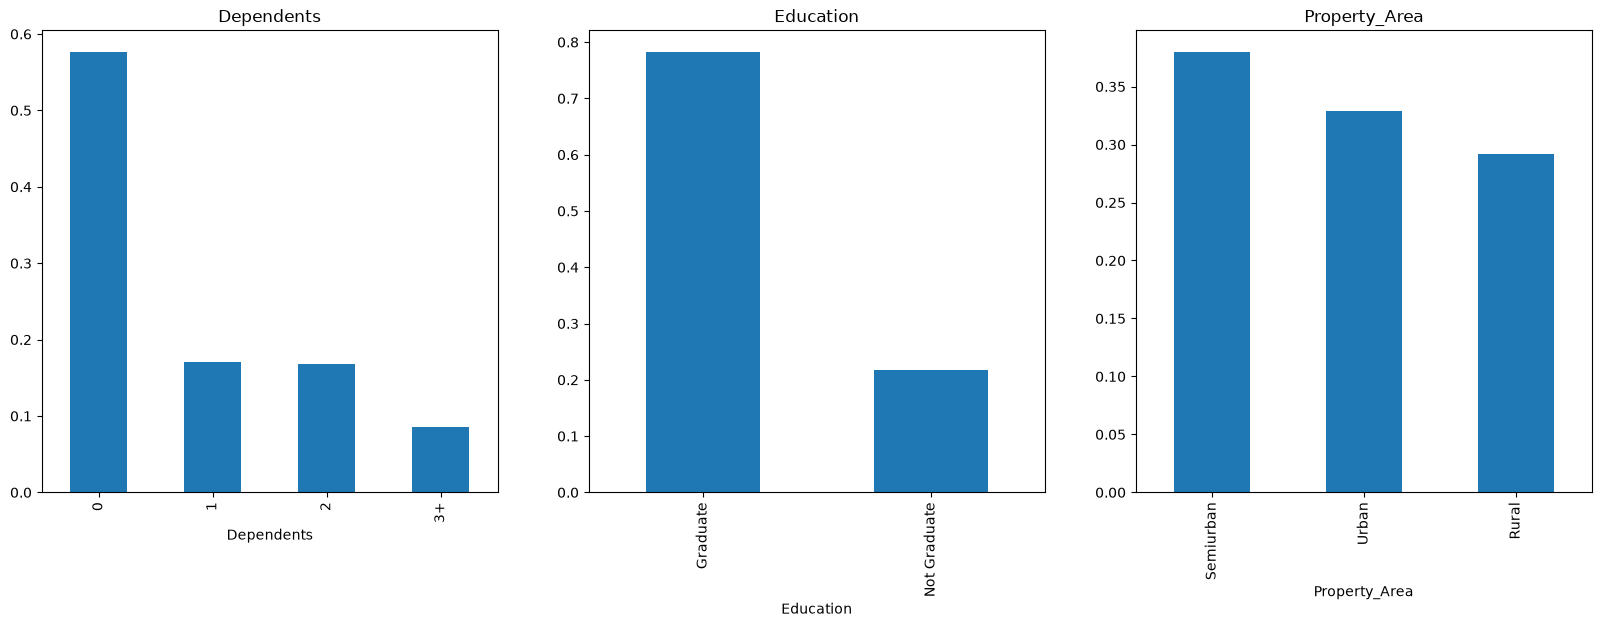

In [230]:
plt.figure(1)
plt.subplot(131)
train['Dependents'].value_counts(normalize=True).plot.bar(figsize = (20,6), title='Dependents')

plt.subplot(132)
train['Education'].value_counts(normalize=True).plot.bar(title= 'Education')

plt.subplot(133)
train['Property_Area' ].value_counts(normalize=True).plot.bar(title= 'Property_Area')

plt.show()

Independent features

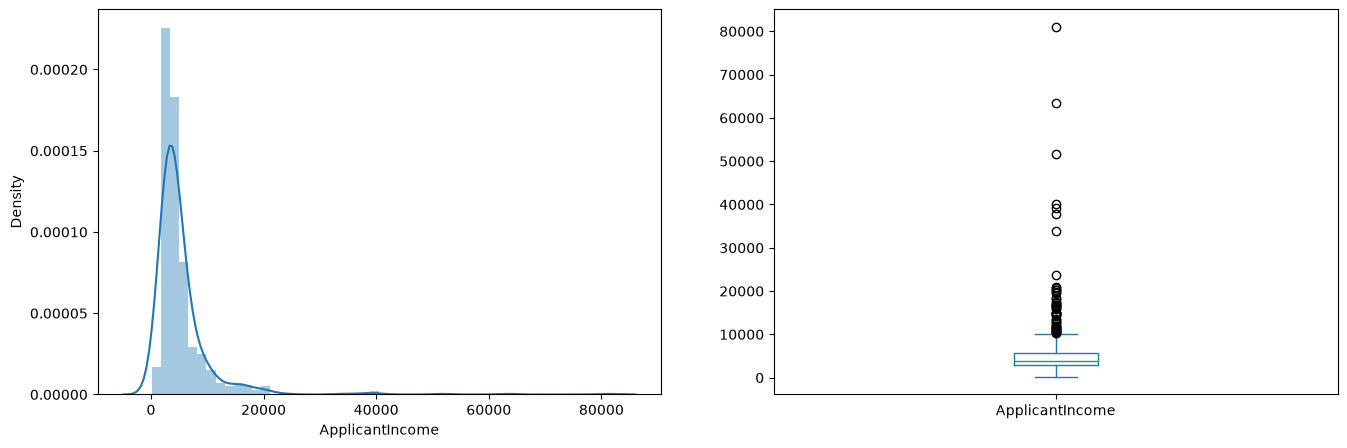

In [231]:
plt.figure(1)
plt.subplot(121)
sns.distplot(train['ApplicantIncome' ])

plt.subplot(122)
train['ApplicantIncome'].plot.box(figsize=(16,5))

plt.show()

. Applicant income is not normally distributed. We should make it normal as algorithm works better if the data is normally distributed.

. Boxplot confirms the presence of outliers/extreme values. This can be attributed to the income disparity in the society.

. Lets segregate them by Education

Text(0.5, 0.98, '')

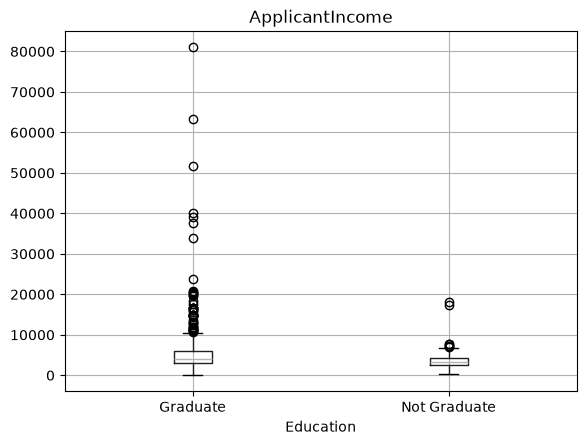

In [232]:
train.boxplot(column="ApplicantIncome", by="Education")
plt.suptitle("")

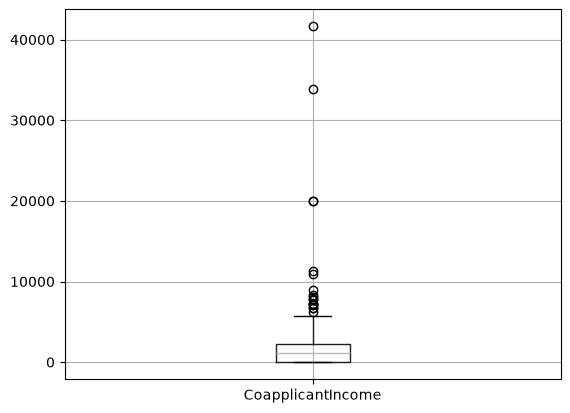

In [233]:
train.boxplot(column="CoapplicantIncome")
plt.show()

<Axes: >

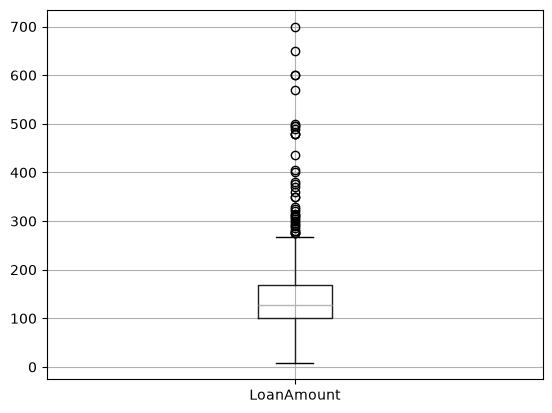

In [234]:
train.boxplot(column="LoanAmount")

# Bivariate Analysis 
Categorical Independent Variable v/s Target Variable

In [235]:
train.columns
train.head(10)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
5,LP001011,Male,Yes,2,Graduate,Yes,5417,4196.0,267.0,360.0,1.0,Urban,Y
6,LP001013,Male,Yes,0,Not Graduate,No,2333,1516.0,95.0,360.0,1.0,Urban,Y
7,LP001014,Male,Yes,3+,Graduate,No,3036,2504.0,158.0,360.0,0.0,Semiurban,N
8,LP001018,Male,Yes,2,Graduate,No,4006,1526.0,168.0,360.0,1.0,Urban,Y
9,LP001020,Male,Yes,1,Graduate,No,12841,10968.0,349.0,360.0,1.0,Semiurban,N


<Axes: xlabel='Gender'>

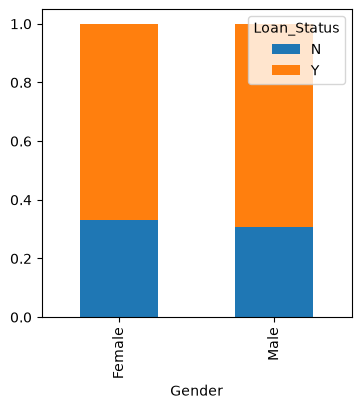

In [236]:
Gender = pd.crosstab(train['Gender'], train['Loan_Status'])
Gender.div(Gender.sum(1).astype(float), axis =0).plot(kind="bar",stacked=True,figsize=(4,4))

<Axes: xlabel='Self_Employed'>

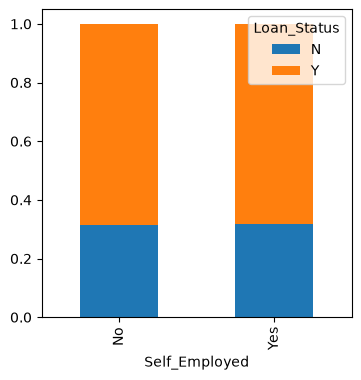

In [237]:
Self_employed = pd.crosstab(train['Self_Employed'], train['Loan_Status'])
Self_employed.div(Self_employed.sum(1).astype(float), axis =0).plot(kind="bar",stacked=True,figsize=(4,4))

<Axes: xlabel='Married'>

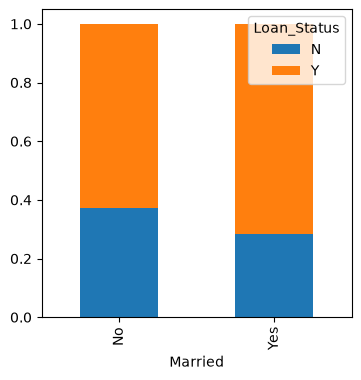

In [238]:
married = pd.crosstab(train['Married'], train['Loan_Status'])
married.div(married.sum(1).astype(float), axis =0).plot(kind="bar",stacked=True,figsize=(4,4))

<Axes: xlabel='Credit_History'>

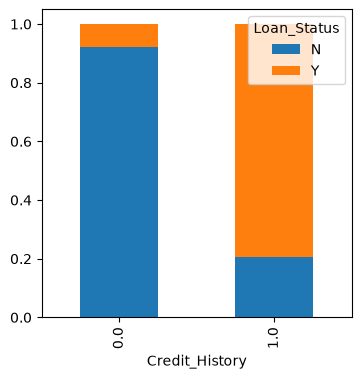

In [239]:
credit_history = pd.crosstab(train['Credit_History'], train['Loan_Status'])
credit_history.div(credit_history.sum(1).astype(float), axis =0).plot(kind="bar",stacked=True,figsize=(4,4))
# here the observation is the people with low credit history mostly not getting the loan

here we can divide the income into some bins and then we can do the comparistions

<Axes: xlabel='Coapplicant_Income_bin'>

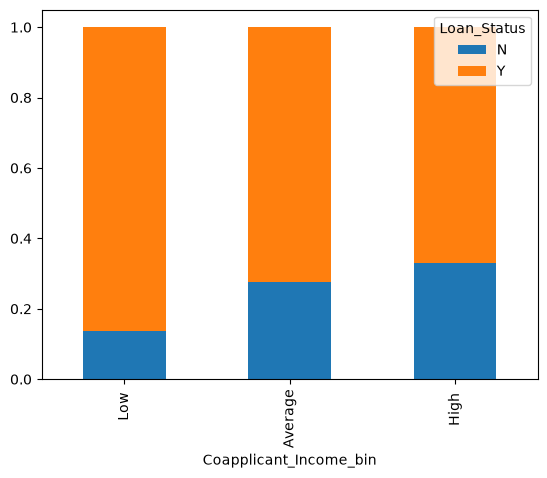

In [240]:
bins = [0,1000,3000,42000] # before creating the bins range we have to go through the data and the we have to desicde the bins range
groups = ["Low ","Average","High "]

train["Coapplicant_Income_bin"] = pd.cut(train["CoapplicantIncome"],bins,labels=groups)

Coapplicant_Income_bin=pd.crosstab(train['Coapplicant_Income_bin'],train['Loan_Status'])
Coapplicant_Income_bin.div(Coapplicant_Income_bin.sum(1).astype(float), axis=0).plot(kind='bar',stacked=True)   


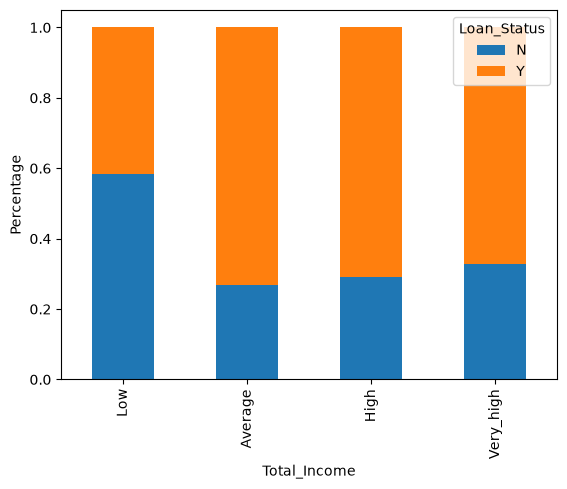

In [241]:
train['Total_Income'] = train['ApplicantIncome'] + train['CoapplicantIncome']

bins = [0,2500,4000,6000,81000]
group = ['Low', 'Average', 'High', 'Very_high']

train['Total_Income_bin']=pd.cut(train['Total_Income'],bins,labels=group)

Total_Income_bin=pd.crosstab(train['Total_Income_bin'],train['Loan_Status'])
Total_Income_bin.div(Total_Income_bin.sum(1).astype(float), axis=0).plot(kind="bar", stacked=True)

plt.xlabel('Total_Income')
P = plt.ylabel('Percentage')

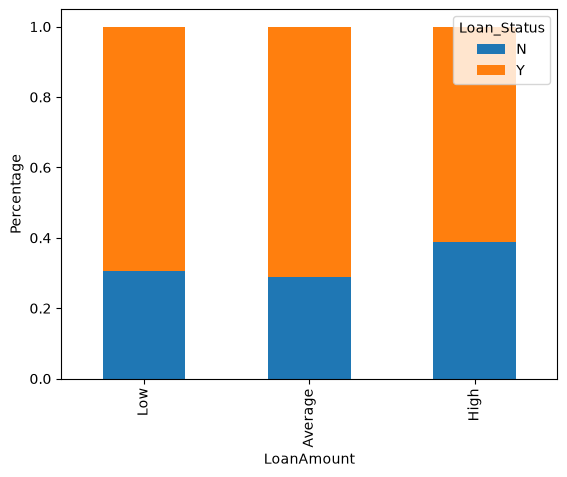

In [242]:
bins=[0,100,200,700]
group=['Low','Average','High']

train['LoanAmount_bin']=pd.cut(train['LoanAmount'],bins,labels=group)

LoanAmount_bin=pd.crosstab(train['LoanAmount_bin'],train['Loan_Status'])
LoanAmount_bin.div(LoanAmount_bin.sum(1).astype(float), axis=0).plot(kind="bar", stacked=True)

plt.xlabel('LoanAmount')
P = plt.ylabel('Percentage')

<Axes: xlabel='Credit_History'>

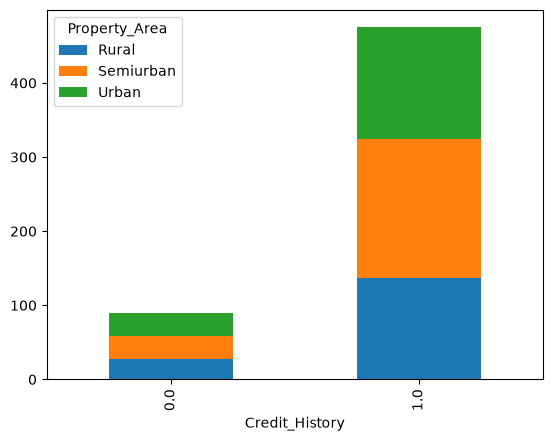

In [243]:
# credit history vs property area bar plot
pd.crosstab(train['Credit_History'], train['Property_Area']).plot(kind='bar',stacked=True)

In [244]:
train.head(20)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,Coapplicant_Income_bin,Total_Income,Total_Income_bin,LoanAmount_bin
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y,NaN,5849.0,High,NaN
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N,Average,6091.0,Very_high,Average
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y,NaN,3000.0,Average,Low
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y,Average,4941.0,High,Average
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y,NaN,6000.0,High,Average
5,LP001011,Male,Yes,2,Graduate,Yes,5417,4196.0,267.0,360.0,1.0,Urban,Y,High,9613.0,Very_high,High
6,LP001013,Male,Yes,0,Not Graduate,No,2333,1516.0,95.0,360.0,1.0,Urban,Y,Average,3849.0,Average,Low
7,LP001014,Male,Yes,3+,Graduate,No,3036,2504.0,158.0,360.0,0.0,Semiurban,N,Average,5540.0,High,Average
8,LP001018,Male,Yes,2,Graduate,No,4006,1526.0,168.0,360.0,1.0,Urban,Y,Average,5532.0,High,Average
9,LP001020,Male,Yes,1,Graduate,No,12841,10968.0,349.0,360.0,1.0,Semiurban,N,High,23809.0,Very_high,High


In [245]:
train = train.drop([ 'Coapplicant_Income_bin', 'LoanAmount_bin', 'Total_Income'], axis=1)

In [246]:
train['Dependents'].replace('3+', 3,inplace=True)
test['Dependents'].replace('3+', 3,inplace=True)
train['Loan_Status'].replace('N', 0,inplace=True)
train['Loan_Status'].replace('Y', 1,inplace=True)

0      1
1      N
2      1
3      1
4      1
      ..
609    1
610    1
611    1
612    1
613    N
Name: Loan_Status, Length: 614, dtype: object

In [247]:
train.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,Total_Income_bin
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y,High
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N,Very_high
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y,Average
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y,High
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y,High


In [248]:
# Now we have to see the realtion b/w features
numerical_df = train.select_dtypes(include=['int64', 'float64'])
# Here are the above code store al numeric features into it

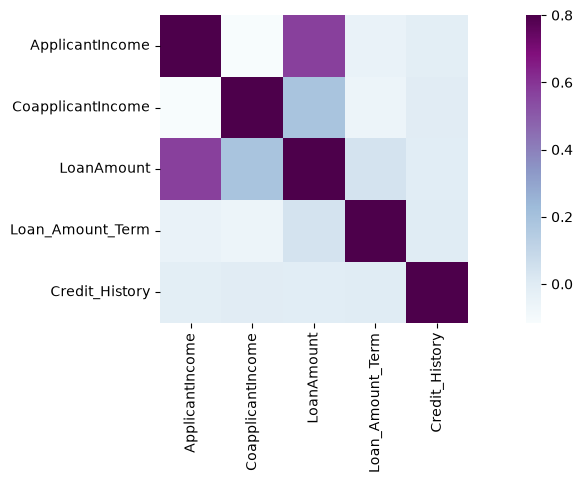

In [249]:
matrix = numerical_df.corr()
f, ax = plt.subplots(figsize=(15,4))
sns.heatmap(matrix, vmax=.8, square=True, cmap="BuPu");

# Missing value Imputation

In [250]:
train.isnull().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
Total_Income_bin      0
dtype: int64

In [251]:
train['Gender'] = train['Gender'].fillna(train['Gender'].mode()[0])
train['Married'] = train['Married'].fillna(train['Married'].mode()[0])
train['Dependents'] = train['Dependents'].fillna(train['Dependents'].mode()[0])
train['Self_Employed'] = train['Self_Employed'].fillna(train['Self_Employed'].mode()[0])
train['Credit_History'] = train['Credit_History'].fillna(train['Credit_History'].mode()[0])

In [252]:
train['Loan_Amount_Term'].value_counts()

Loan_Amount_Term
360.0    512
180.0     44
480.0     15
300.0     13
240.0      4
84.0       4
120.0      3
60.0       2
36.0       2
12.0       1
Name: count, dtype: int64

In [253]:
train['Loan_Amount_Term'] = train['Loan_Amount_Term'].fillna(train['Loan_Amount_Term'].mode()[0])
train['LoanAmount'] = train['LoanAmount'].fillna(train['LoanAmount'].median())

In [254]:
train.isnull().sum()

Loan_ID              0
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
Total_Income_bin     0
dtype: int64

In [255]:
# Fill categorical and numerical columns in the test set using train statistics
test['Gender'] = test['Gender'].fillna(train['Gender'].mode()[0])
test['Dependents'] = test['Dependents'].fillna(train['Dependents'].mode()[0])
test['Self_Employed'] = test['Self_Employed'].fillna(train['Self_Employed'].mode()[0])
test['Credit_History'] = test['Credit_History'].fillna(train['Credit_History'].mode()[0])
test['Loan_Amount_Term'] = test['Loan_Amount_Term'].fillna(train['Loan_Amount_Term'].mode()[0])
test['LoanAmount'] = test['LoanAmount'].fillna(train['LoanAmount'].median())

In [261]:
test.isna().sum()

Loan_ID              0
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
LoanAmount_log       0
dtype: int64

# Out layer treatment

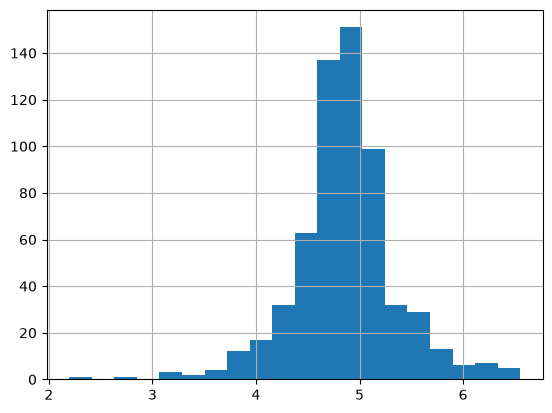

In [256]:
# Out layers means the values which are in different range from all other values and that values effects the remaining
# We havr to remove them or tranform them by appling log 
train["LoanAmount_log"] = np.log(train["LoanAmount"])
train["LoanAmount_log"].hist(bins=20)
test["LoanAmount_log"] = np.log(test["LoanAmount"])
 

# Feature Engineering

1. Binary Encoding 
2. One-Hot-Encoding
3. Label Encoding

In [262]:
train.set_index('Loan_ID',inplace=True)
test.set_index('Loan_ID',inplace=True)

In [263]:
train.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,Total_Income_bin,LoanAmount_log
Loan_ID,,,,,,,,,,,,,,
LP001002,1,0,0,1,0,5849,0.0,128.0,360.0,1.0,Urban,Y,High,4.852030
LP001003,1,1,1,1,0,4583,1508.0,128.0,360.0,1.0,Rural,N,Very_high,4.852030
LP001005,1,1,0,1,1,3000,0.0,66.0,360.0,1.0,Urban,Y,Average,4.189655
LP001006,1,1,0,0,0,2583,2358.0,120.0,360.0,1.0,Urban,Y,High,4.787492
LP001008,1,0,0,1,0,6000,0.0,141.0,360.0,1.0,Urban,Y,High,4.948760


In [264]:
# drop the features
train.drop(['Total_Income_bin','LoanAmount_log'],axis=1,inplace=True)
train.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
Loan_ID,,,,,,,,,,,,
LP001002,1,0,0,1,0,5849,0.0,128.0,360.0,1.0,Urban,Y
LP001003,1,1,1,1,0,4583,1508.0,128.0,360.0,1.0,Rural,N
LP001005,1,1,0,1,1,3000,0.0,66.0,360.0,1.0,Urban,Y
LP001006,1,1,0,0,0,2583,2358.0,120.0,360.0,1.0,Urban,Y
LP001008,1,0,0,1,0,6000,0.0,141.0,360.0,1.0,Urban,Y


In [265]:
test.drop(['LoanAmount_log'],axis=1,inplace=True)
test.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area
Loan_ID,,,,,,,,,,,
LP001015,1,1,0,1,0,5720,0,110.0,360.0,1.0,Urban
LP001022,1,1,1,1,0,3076,1500,126.0,360.0,1.0,Urban
LP001031,1,1,2,1,0,5000,1800,208.0,360.0,1.0,Urban
LP001035,1,1,2,1,0,2340,2546,100.0,360.0,1.0,Urban
LP001051,1,0,0,0,0,3276,0,78.0,360.0,1.0,Urban


In [266]:
print(train.columns)
print(test.columns)

Index(['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed',
       'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status'],
      dtype='str')
Index(['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed',
       'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area'],
      dtype='str')


In [257]:
# binary encoding on train data
train['Gender'] = train['Gender'].map({'Male': 1, 'Female': 0})
train['Married'] = train['Married'].map({'Yes': 1, 'No': 0})
train['Education'] = train['Education'].map({'Graduate': 1, 'Not Graduate': 0})
train['Self_Employed'] = train['Self_Employed'].map({'Yes': 1, 'No': 0})

In [258]:
# binary encoding on test data
test['Gender'] = test['Gender'].map({'Male': 1, 'Female': 0})
test['Married'] = test['Married'].map({'Yes': 1, 'No': 0})
test['Education'] = test['Education'].map({'Graduate': 1, 'Not Graduate': 0})
test['Self_Employed'] = test['Self_Employed'].map({'Yes': 1, 'No': 0})

In [259]:
train.head(20)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,Total_Income_bin,LoanAmount_log
0,LP001002,1,0,0,1,0,5849,0.0,128.0,360.0,1.0,Urban,Y,High,4.852030
1,LP001003,1,1,1,1,0,4583,1508.0,128.0,360.0,1.0,Rural,N,Very_high,4.852030
2,LP001005,1,1,0,1,1,3000,0.0,66.0,360.0,1.0,Urban,Y,Average,4.189655
3,LP001006,1,1,0,0,0,2583,2358.0,120.0,360.0,1.0,Urban,Y,High,4.787492
4,LP001008,1,0,0,1,0,6000,0.0,141.0,360.0,1.0,Urban,Y,High,4.948760
5,LP001011,1,1,2,1,1,5417,4196.0,267.0,360.0,1.0,Urban,Y,Very_high,5.587249
6,LP001013,1,1,0,0,0,2333,1516.0,95.0,360.0,1.0,Urban,Y,Average,4.553877
7,LP001014,1,1,3+,1,0,3036,2504.0,158.0,360.0,0.0,Semiurban,N,High,5.062595
8,LP001018,1,1,2,1,0,4006,1526.0,168.0,360.0,1.0,Urban,Y,High,5.123964
9,LP001020,1,1,1,1,0,12841,10968.0,349.0,360.0,1.0,Semiurban,N,Very_high,5.855072


In [267]:
# train data
train['Dependents'] = train['Dependents'].replace('3+', 3).astype(int)

In [268]:
# test data
test['Dependents'] = test['Dependents'].replace('3+', 3).astype(int)

One-hot-encoding

In [273]:
# train data
train_df_encoded = pd.get_dummies(train, columns=['Property_Area'], drop_first=True)
train_df_encoded.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Loan_Status,Property_Area_Semiurban,Property_Area_Urban
Loan_ID,,,,,,,,,,,,,
LP001002,1,0,0,1,0,5849,0.0,128.0,360.0,1.0,Y,False,True
LP001003,1,1,1,1,0,4583,1508.0,128.0,360.0,1.0,N,False,False
LP001005,1,1,0,1,1,3000,0.0,66.0,360.0,1.0,Y,False,True
LP001006,1,1,0,0,0,2583,2358.0,120.0,360.0,1.0,Y,False,True
LP001008,1,0,0,1,0,6000,0.0,141.0,360.0,1.0,Y,False,True


In [274]:
# test data
test_df_encoded = pd.get_dummies(test, columns=['Property_Area'], drop_first=True)
test_df_encoded.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area_Semiurban,Property_Area_Urban
Loan_ID,,,,,,,,,,,,
LP001015,1,1,0,1,0,5720,0,110.0,360.0,1.0,False,True
LP001022,1,1,1,1,0,3076,1500,126.0,360.0,1.0,False,True
LP001031,1,1,2,1,0,5000,1800,208.0,360.0,1.0,False,True
LP001035,1,1,2,1,0,2340,2546,100.0,360.0,1.0,False,True
LP001051,1,0,0,0,0,3276,0,78.0,360.0,1.0,False,True


In [277]:
train_df_encoded.dtypes

Gender                       int64
Married                      int64
Dependents                   int64
Education                    int64
Self_Employed                int64
ApplicantIncome              int64
CoapplicantIncome          float64
LoanAmount                 float64
Loan_Amount_Term           float64
Credit_History             float64
Loan_Status                    str
Property_Area_Semiurban       bool
Property_Area_Urban           bool
dtype: object

In [278]:
# Map 'Y' and 'N' to 1 and 0
train_df_encoded['Loan_Status'] = train_df_encoded['Loan_Status'].map({'Y': 1, 'N': 0})

In [281]:
# train df
train_df_encoded = train_df_encoded.astype(int)
train_df_encoded.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Loan_Status,Property_Area_Semiurban,Property_Area_Urban
Loan_ID,,,,,,,,,,,,,
LP001002,1,0,0,1,0,5849,0,128,360,1,1,0,1
LP001003,1,1,1,1,0,4583,1508,128,360,1,0,0,0
LP001005,1,1,0,1,1,3000,0,66,360,1,1,0,1
LP001006,1,1,0,0,0,2583,2358,120,360,1,1,0,1
LP001008,1,0,0,1,0,6000,0,141,360,1,1,0,1


In [280]:
# train df
test_df_encoded = test_df_encoded.astype(int)
test_df_encoded.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area_Semiurban,Property_Area_Urban
Loan_ID,,,,,,,,,,,,
LP001015,1,1,0,1,0,5720,0,110,360,1,0,1
LP001022,1,1,1,1,0,3076,1500,126,360,1,0,1
LP001031,1,1,2,1,0,5000,1800,208,360,1,0,1
LP001035,1,1,2,1,0,2340,2546,100,360,1,0,1
LP001051,1,0,0,0,0,3276,0,78,360,1,0,1


Label Encoding

In [313]:
# lable encoding on property area column
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()

# train data label encoding
train['Property_Area'] = le.fit_transform(train['Property_Area'])
train.head(10)

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
Loan_ID,,,,,,,,,,,,
LP001002,1,0,0,1,0,5849,0.0,128.0,360.0,1.0,2,Y
LP001003,1,1,1,1,0,4583,1508.0,128.0,360.0,1.0,0,N
LP001005,1,1,0,1,1,3000,0.0,66.0,360.0,1.0,2,Y
LP001006,1,1,0,0,0,2583,2358.0,120.0,360.0,1.0,2,Y
LP001008,1,0,0,1,0,6000,0.0,141.0,360.0,1.0,2,Y
LP001011,1,1,2,1,1,5417,4196.0,267.0,360.0,1.0,2,Y
LP001013,1,1,0,0,0,2333,1516.0,95.0,360.0,1.0,2,Y
LP001014,1,1,3,1,0,3036,2504.0,158.0,360.0,0.0,1,N
LP001018,1,1,2,1,0,4006,1526.0,168.0,360.0,1.0,2,Y


In [314]:
test['Property_Area'] = le.fit_transform(test['Property_Area'])
test.head(10)

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area
Loan_ID,,,,,,,,,,,
LP001015,1,1,0,1,0,5720,0,110.0,360.0,1.0,2
LP001022,1,1,1,1,0,3076,1500,126.0,360.0,1.0,2
LP001031,1,1,2,1,0,5000,1800,208.0,360.0,1.0,2
LP001035,1,1,2,1,0,2340,2546,100.0,360.0,1.0,2
LP001051,1,0,0,0,0,3276,0,78.0,360.0,1.0,2
LP001054,1,1,0,0,1,2165,3422,152.0,360.0,1.0,2
LP001055,0,0,1,0,0,2226,0,59.0,360.0,1.0,1
LP001056,1,1,2,0,0,3881,0,147.0,360.0,0.0,0
LP001059,1,1,2,1,0,13633,0,280.0,240.0,1.0,2


Train and split the data

In [284]:
from sklearn.model_selection import train_test_split

In [286]:
X = train.drop(['Loan_Status'],axis=1)
y = train["Loan_Status"]

In [287]:
X

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area
Loan_ID,,,,,,,,,,,
LP001002,1,0,0,1,0,5849,0.0,128.0,360.0,1.0,2
LP001003,1,1,1,1,0,4583,1508.0,128.0,360.0,1.0,0
LP001005,1,1,0,1,1,3000,0.0,66.0,360.0,1.0,2
LP001006,1,1,0,0,0,2583,2358.0,120.0,360.0,1.0,2
LP001008,1,0,0,1,0,6000,0.0,141.0,360.0,1.0,2
...,...,...,...,...,...,...,...,...,...,...,...
LP002978,0,0,0,1,0,2900,0.0,71.0,360.0,1.0,0
LP002979,1,1,3,1,0,4106,0.0,40.0,180.0,1.0,0
LP002983,1,1,1,1,0,8072,240.0,253.0,360.0,1.0,2


In [288]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [289]:
X_train.shape

(491, 11)

# building base models

In [290]:
# KNN
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train,y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](2,)","['N','Y']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [291]:
print("Train score",knn.score(X_train,y_train))
print("Test Score",knn.score(X_test,y_test))

Train score 0.7352342158859471
Test Score 0.5772357723577236


In [292]:
scores = []
for k in range(1,40):
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train,y_train)
    scores.append(knn.score(X_test,y_test))
scores

[0.5853658536585366,
 0.5528455284552846,
 0.6178861788617886,
 0.5609756097560976,
 0.5772357723577236,
 0.5691056910569106,
 0.5853658536585366,
 0.5853658536585366,
 0.5772357723577236,
 0.5609756097560976,
 0.6016260162601627,
 0.5853658536585366,
 0.5934959349593496,
 0.5853658536585366,
 0.6097560975609756,
 0.6178861788617886,
 0.6260162601626016,
 0.6341463414634146,
 0.6178861788617886,
 0.6178861788617886,
 0.6504065040650406,
 0.6260162601626016,
 0.6260162601626016,
 0.6260162601626016,
 0.6666666666666666,
 0.6504065040650406,
 0.6504065040650406,
 0.6422764227642277,
 0.6504065040650406,
 0.6504065040650406,
 0.6504065040650406,
 0.6504065040650406,
 0.6504065040650406,
 0.6585365853658537,
 0.6504065040650406,
 0.6585365853658537,
 0.6504065040650406,
 0.6504065040650406,
 0.6504065040650406]

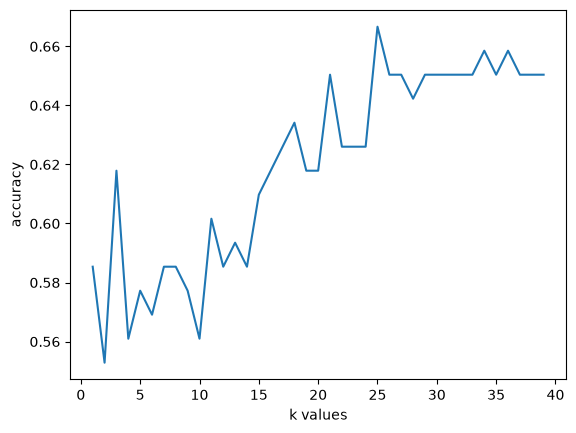

In [294]:
# graph for k values
plt.plot(range(1, 40), scores)
plt.xlabel('k values')
plt.ylabel('accuracy')
plt.show()

In [296]:
# from the above graph we can observe when k values is 25 we have more accuracy
knn = KNeighborsClassifier(n_neighbors=25)
knn.fit(X_train,y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",25
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](2,)","['N','Y']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [297]:
#score
print("KNN train Score: ",knn.score(X_train, y_train))
print("KNN test Score: ",knn.score(X_test, y_test))

KNN train Score:  0.7087576374745418
KNN test Score:  0.6666666666666666


In [298]:
# accuracy
from sklearn.metrics import accuracy_score
y_pred = knn.predict(X_test)
KNN_accuracy = accuracy_score(y_test, y_pred)
KNN_accuracy

0.6666666666666666

In [300]:
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           N       1.00      0.05      0.09        43
           Y       0.66      1.00      0.80        80

    accuracy                           0.67       123
   macro avg       0.83      0.52      0.44       123
weighted avg       0.78      0.67      0.55       123



In [302]:
# Building SVM
from sklearn.svm import SVC 

svm = SVC(kernel="linear")
svm.fit(X_train,y_train)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [303]:
# score
print("SVM train Score: ",svm.score(X_train, y_train))
print("SVM train Score: ",svm.score(X_test, y_test))

SVM train Score:  0.7963340122199593
SVM train Score:  0.7886178861788617


In [304]:
# accuracy
y_pred = svm.predict(X_test)
SVM_accuracy = accuracy_score(y_test, y_pred)
print("SVM Accuracy: ",SVM_accuracy)

SVM Accuracy:  0.7886178861788617


In [305]:
#classification report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           N       1.00      0.40      0.57        43
           Y       0.75      1.00      0.86        80

    accuracy                           0.79       123
   macro avg       0.88      0.70      0.71       123
weighted avg       0.84      0.79      0.76       123



In [306]:
#Building Decision Tree
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier(criterion='entropy',max_depth=3)
dt.fit(X_train,y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sampl

In [307]:
#accuracy
y_pred = dt.predict(X_test)
DT_accuracy = accuracy_score(y_test, y_pred)
print("Decision Tree Accuracy: ",DT_accuracy)

Decision Tree Accuracy:  0.7886178861788617


In [308]:
#classification report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           N       0.95      0.42      0.58        43
           Y       0.76      0.99      0.86        80

    accuracy                           0.79       123
   macro avg       0.85      0.70      0.72       123
weighted avg       0.83      0.79      0.76       123



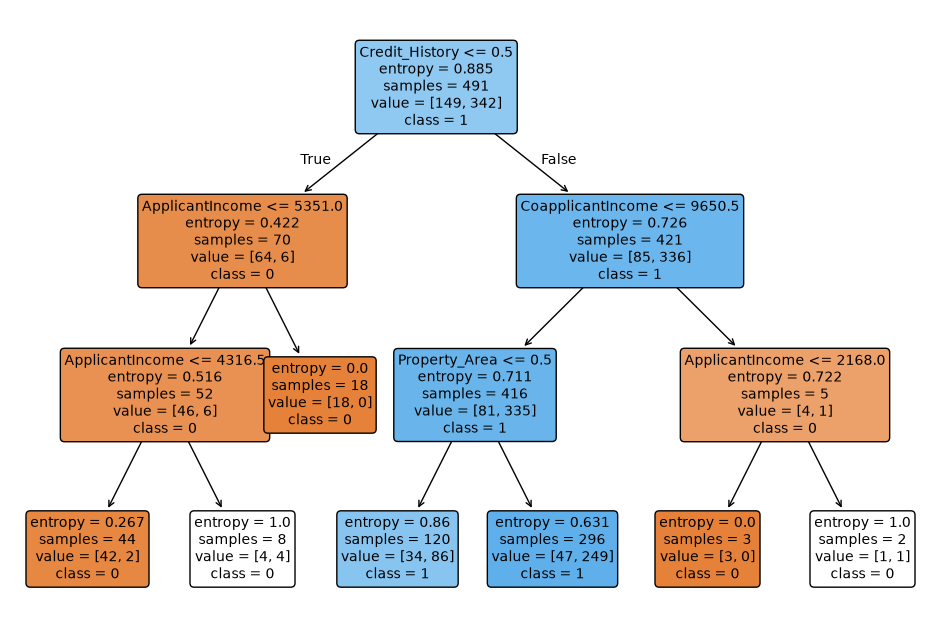

In [310]:
# visualize decision tree
from sklearn.tree import plot_tree

# Plot the decision tree
plt.figure(figsize=(12, 8))
plot_tree(dt,
          feature_names=X.columns,
          class_names=['0', '1'],
          filled=True,
          rounded=True,
          fontsize=10
          )
plt.show()

Model performance on test

In [315]:
# Predict on the test dataset knn
test_predictions_knn = knn.predict(test)

# Save predictions to csv file
output = pd.DataFrame({'Loan_ID': test_original['Loan_ID'], 'Loan_Status': test_predictions_knn})
output.to_csv("test_predictions_knn.csv", index=False)

In [316]:
# Predict on the test dataset svm
test_predictions_svm = svm.predict(test)

# Save predictions to csv file
output = pd.DataFrame({'Loan_ID': test_original['Loan_ID'], 'Loan_Status': test_predictions_svm})
output.to_csv("test_predictions_svm.csv", index=False)

In [317]:
# Predict on the test dataset knn
test_predictions_dt = dt.predict(test)

# Save predictions to csv file
output = pd.DataFrame({'Loan_ID': test_original['Loan_ID'], 'Loan_Status': test_predictions_dt})
output.to_csv("test_predictions_dt.csv", index=False)

Model comparistion

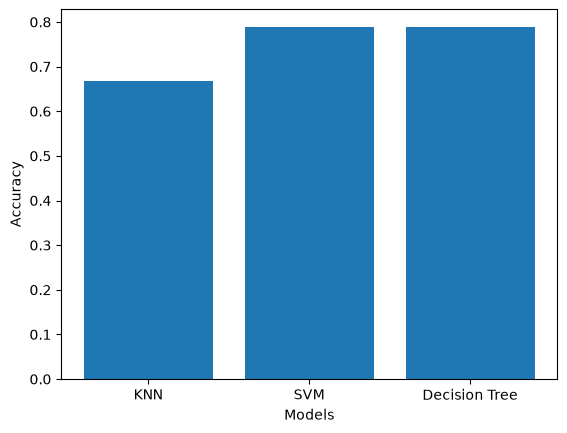

In [318]:
# bar plot for comaring model results
models = ['KNN', 'SVM', 'Decision Tree']
accuracy = [KNN_accuracy, SVM_accuracy, DT_accuracy]
plt.bar(models, accuracy)
plt.xlabel('Models')
plt.ylabel('Accuracy')
plt.show()

# Feature Engineering-2

Now we are doing to do LOFO (leave one feature out)
* LOFO systematically removes one feature at a time from the dataset.

* The model is re-trained without this feature, and the performance
(e.g., accuracy, F1-score) is compared to the baseline performance of
the full model.

 * A larger performance drop indicates greater importance of the
removed feature.

In [319]:
train['ApplicantIncome_log'] = np.log(train['ApplicantIncome'])
train['LoanAmount_log'] = np.log(train['LoanAmount'])

In [320]:
train.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,ApplicantIncome_log,LoanAmount_log
Loan_ID,,,,,,,,,,,,,,
LP001002,1,0,0,1,0,5849,0.0,128.0,360.0,1.0,2,Y,8.674026,4.852030
LP001003,1,1,1,1,0,4583,1508.0,128.0,360.0,1.0,0,N,8.430109,4.852030
LP001005,1,1,0,1,1,3000,0.0,66.0,360.0,1.0,2,Y,8.006368,4.189655
LP001006,1,1,0,0,0,2583,2358.0,120.0,360.0,1.0,2,Y,7.856707,4.787492
LP001008,1,0,0,1,0,6000,0.0,141.0,360.0,1.0,2,Y,8.699515,4.948760


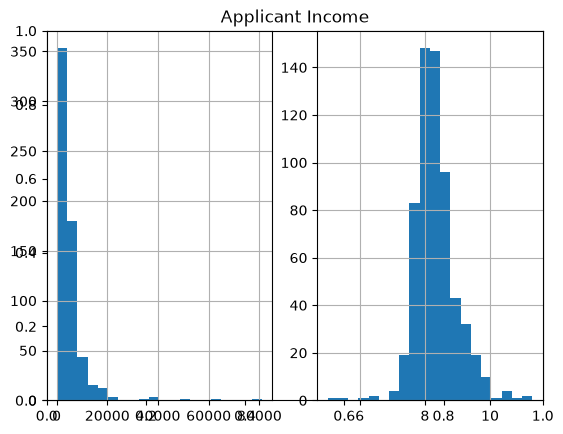

In [321]:
plt.figure(1)
plt.title("Applicant Income")

plt.subplot(121)
train['ApplicantIncome'].hist(bins=20)

plt.subplot(122)
train['ApplicantIncome_log'].hist(bins=20)

plt.show()

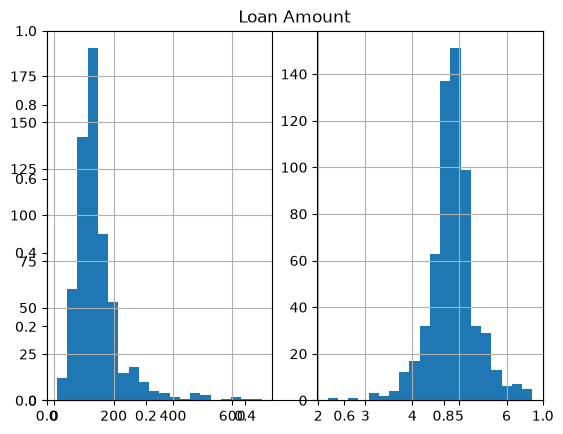

In [322]:
plt.figure(1)
plt.title("Loan Amount")

plt.subplot(121)
train['LoanAmount'].hist(bins=20)

plt.subplot(122)
train['LoanAmount_log'].hist(bins=20)

plt.show()

In [325]:
train['CoapplicantIncome_log_offset'] = np.log(train['CoapplicantIncome'] + 1)

In [326]:
# sqrt on coapplicant
train['CoapplicantIncome_log'] = np.sqrt(train['CoapplicantIncome'])

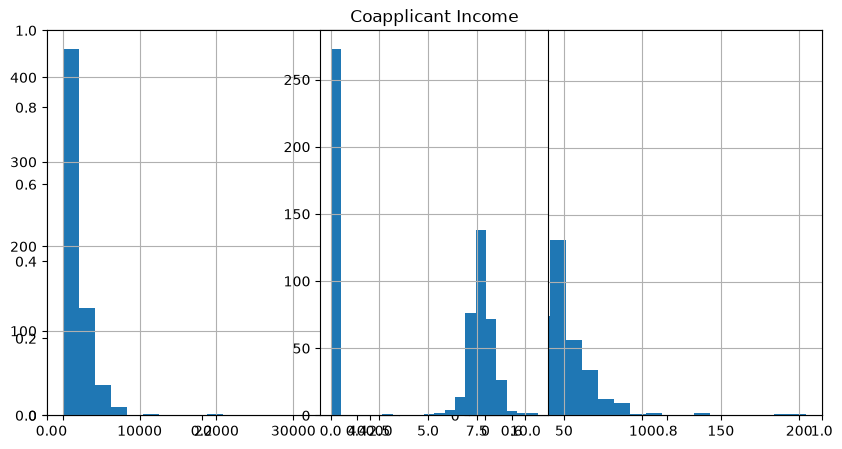

In [327]:
plt.figure(figsize = (10,5))
plt.title("Coapplicant Income")

plt.subplot(121)
train['CoapplicantIncome'].hist(bins=20)

plt.subplot(122)
train['CoapplicantIncome_log'].hist(bins=20)

plt.subplot(132)
train['CoapplicantIncome_log_offset'].hist(bins=20)

plt.show()

In [328]:
train.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,ApplicantIncome_log,LoanAmount_log,CoapplicantIncome_log,CoapplicantIncome_log_offset
Loan_ID,,,,,,,,,,,,,,,,
LP001002,1,0,0,1,0,5849,0.0,128.0,360.0,1.0,2,Y,8.674026,4.852030,0.000000,0.000000
LP001003,1,1,1,1,0,4583,1508.0,128.0,360.0,1.0,0,N,8.430109,4.852030,38.832976,7.319202
LP001005,1,1,0,1,1,3000,0.0,66.0,360.0,1.0,2,Y,8.006368,4.189655,0.000000,0.000000
LP001006,1,1,0,0,0,2583,2358.0,120.0,360.0,1.0,2,Y,7.856707,4.787492,48.559242,7.765993
LP001008,1,0,0,1,0,6000,0.0,141.0,360.0,1.0,2,Y,8.699515,4.948760,0.000000,0.000000


In [329]:
train.drop(['ApplicantIncome','LoanAmount','CoapplicantIncome_log_offset','CoapplicantIncome'],axis=1,inplace=True)

In [330]:
train.head()

,Gender,Married,Dependents,Education,Self_Employed,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,ApplicantIncome_log,LoanAmount_log,CoapplicantIncome_log
Loan_ID,,,,,,,,,,,,
LP001002,1,0,0,1,0,360.0,1.0,2,Y,8.674026,4.852030,0.000000
LP001003,1,1,1,1,0,360.0,1.0,0,N,8.430109,4.852030,38.832976
LP001005,1,1,0,1,1,360.0,1.0,2,Y,8.006368,4.189655,0.000000
LP001006,1,1,0,0,0,360.0,1.0,2,Y,7.856707,4.787492,48.559242
LP001008,1,0,0,1,0,360.0,1.0,2,Y,8.699515,4.948760,0.000000


In [331]:
test['ApplicantIncome_log'] = np.log(test['ApplicantIncome'])
test['LoanAmount_log'] = np.log(test['LoanAmount'])
test['CoapplicantIncome_log'] = np.sqrt(test['CoapplicantIncome'])

test.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,ApplicantIncome_log,LoanAmount_log,CoapplicantIncome_log
Loan_ID,,,,,,,,,,,,,,
LP001015,1,1,0,1,0,5720,0,110.0,360.0,1.0,2,8.651724,4.700480,0.000000
LP001022,1,1,1,1,0,3076,1500,126.0,360.0,1.0,2,8.031385,4.836282,38.729833
LP001031,1,1,2,1,0,5000,1800,208.0,360.0,1.0,2,8.517193,5.337538,42.426407
LP001035,1,1,2,1,0,2340,2546,100.0,360.0,1.0,2,7.757906,4.605170,50.457903
LP001051,1,0,0,0,0,3276,0,78.0,360.0,1.0,2,8.094378,4.356709,0.000000


In [332]:
test.drop(['ApplicantIncome','LoanAmount','CoapplicantIncome'],axis=1,inplace=True)

Re iter on base models

In [333]:
X = train.drop("Loan_Status",axis=1)
y = train["Loan_Status"]

In [334]:
# train test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [335]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(491, 11)
(123, 11)
(491,)
(123,)


In [336]:
# build Decision tree
dt = DecisionTreeClassifier(criterion='entropy', max_depth=3)
dt.fit(X_train, y_train)

#baseline score
y_pred = dt.predict(X_test)
DT_accuracy = accuracy_score(y_test, y_pred)
print("Decision Tree Accuracy: ",DT_accuracy)

Decision Tree Accuracy:  0.7886178861788617


In [337]:
#build SVM
svm = SVC(kernel='linear')
svm.fit(X_train, y_train)

#baseline score
y_pred = svm.predict(X_test)
SVM_accuracy = accuracy_score(y_test, y_pred)
print("SVM Accuracy: ",SVM_accuracy)

SVM Accuracy:  0.7886178861788617


LOFO

In [338]:
feature_importance = {}

for feature in X.columns:

    # Drop one feature
    X_train_reduced = X_train.drop(columns=[feature])
    X_test_reduced = X_test.drop(columns=[feature])

    # Train and evaluate the model
    dt.fit(X_train_reduced, y_train)
    y_pred_reduced = dt.predict(X_test_reduced)

    reduced_accuracy = accuracy_score(y_test, y_pred_reduced)

    # Compute the performance drop
    performance_drop = DT_accuracy - reduced_accuracy
    feature_importance[feature] = performance_drop

# rank features by importance
sorted_importance = sorted(feature_importance.items(), key=lambda x: x[1], reverse=True)

print("\nFeature Importance (LOFO):")
for feature, drop in sorted_importance:
    print(f"{feature}: Performance Drop = {drop:.4f}")


Feature Importance (LOFO):
Credit_History: Performance Drop = 0.1545
Gender: Performance Drop = 0.0000
Married: Performance Drop = 0.0000
Dependents: Performance Drop = 0.0000
Education: Performance Drop = 0.0000
Self_Employed: Performance Drop = 0.0000
Loan_Amount_Term: Performance Drop = 0.0000
Property_Area: Performance Drop = 0.0000
ApplicantIncome_log: Performance Drop = 0.0000
LoanAmount_log: Performance Drop = 0.0000
CoapplicantIncome_log: Performance Drop = 0.0000


In [339]:
feature_importance = {}

for feature in X.columns:

    # Drop one feature
    X_train_reduced = X_train.drop(columns=[feature])
    X_test_reduced = X_test.drop(columns=[feature])

    # Train and evaluate the model
    svm.fit(X_train_reduced, y_train)
    y_pred_reduced = svm.predict(X_test_reduced)

    reduced_accuracy = accuracy_score(y_test, y_pred_reduced)

    # Compute the performance drop
    performance_drop = SVM_accuracy - reduced_accuracy
    feature_importance[feature] = performance_drop

# rank features by importance
sorted_importance = sorted(feature_importance.items(), key=lambda x: x[1], reverse=True)

print("\nFeature Importance (LOFO):")
for feature, drop in sorted_importance:
    print(f"{feature}: Performance Drop = {drop:.4f}")


Feature Importance (LOFO):
Credit_History: Performance Drop = 0.1382
Gender: Performance Drop = 0.0000
Married: Performance Drop = 0.0000
Dependents: Performance Drop = 0.0000
Education: Performance Drop = 0.0000
Self_Employed: Performance Drop = 0.0000
Loan_Amount_Term: Performance Drop = 0.0000
Property_Area: Performance Drop = 0.0000
ApplicantIncome_log: Performance Drop = 0.0000
LoanAmount_log: Performance Drop = 0.0000
CoapplicantIncome_log: Performance Drop = 0.0000


**Interpretation:**
- Credit_History (Performance Drop = 0.1545):

  1. This feature has the highest performance drop, meaning it is the most critical predictor for the model's accuracy.
  2. Removing this feature significantly impacts the model's ability to make correct predictions.

- Other Features (Performance Drop = 0.0000):

  1. For all other features (Gender, Married, Dependents, Education, etc.), the performance drop is zero.
  2. This suggests that these features do not contribute significantly to the model's predictions. In essence, the model's performance remains unchanged even if these features are excluded.

## Actionable Insights Based on LOFO

- For Positive Values: Retain these features; they are contributing positively.
- For Negative Values: Consider dropping these features, as they may be redundant or harmful to the model.
- For Zero Values: Evaluate whether these features are necessary, as they may not contribute meaningfully.

In [340]:
X = train.drop('Loan_Status',axis=1)
y = train['Loan_Status']

In [341]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [342]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(491, 11)
(123, 11)
(491,)
(123,)


In [343]:
dt = DecisionTreeClassifier(criterion='entropy',max_depth=3)
dt.fit(X_train,y_train)

y_pred = dt.predict(X_test)
DT_accuracy = accuracy_score(y_test,y_pred)
print("Decision Tree Accuracy: ",DT_accuracy)

Decision Tree Accuracy:  0.7886178861788617


# Final model with hyperparameter tuning

In [344]:
from sklearn.model_selection import GridSearchCV,RandomizedSearchCV

In [345]:
train.columns

Index(['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status',
       'ApplicantIncome_log', 'LoanAmount_log', 'CoapplicantIncome_log'],
      dtype='str')

In [346]:
X = train[['Loan_Amount_Term','Credit_History','ApplicantIncome_log','LoanAmount_log','CoapplicantIncome_log']]
Y = train['Loan_Status']

In [347]:
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

In [349]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(491, 5)
(123, 5)
(491,)
(123,)


In [350]:
# Train the Decision Tree Classifier
dt_model = DecisionTreeClassifier(criterion='entropy',
                                  random_state=42)
dt_model.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samp

In [351]:
# hyperparameter grid
param_grid = {
    'max_depth': [3, 5, 7, 10, 15],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 5, 10, 20],
    'max_leaf_nodes': [10, 20, 50]
}

In [352]:
# Initialize GridSearchCV with 5-fold cross-validation
grid_search = GridSearchCV(estimator=dt_model,
                           param_grid=param_grid,
                           cv=5,
                           scoring='accuracy',
                           n_jobs = -1, # use all cpu cores
                           verbose = 2 # print progress
                           )

In [353]:
# Fit Grid Search to the training data
grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 240 candidates, totalling 1200 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [3, 5, ...], 'max_leaf_nodes': [10, 20, ...], 'min_samples_leaf': [1, 5, ...], 'min_samples_split': [2, 5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_au

In [354]:
print("Best Hyperparameters from Grid Search:", grid_search.best_params_)

Best Hyperparameters from Grid Search: {'max_depth': 3, 'max_leaf_nodes': 10, 'min_samples_leaf': 20, 'min_samples_split': 2}


In [355]:
# Evaluate the model with the best parameters on the test set
best_dt_model = grid_search.best_estimator_
y_pred = best_dt_model.predict(X_test)

In [356]:
# Predict on training and testing data
train_preds = best_dt_model.predict(X_train)
test_preds = best_dt_model.predict(X_test)

# Calculate accuracy
train_accuracy = accuracy_score(y_train, train_preds)
test_accuracy = accuracy_score(y_test, y_pred)

print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Testing Accuracy: {test_accuracy:.4f}")

Training Accuracy: 0.8147
Testing Accuracy: 0.7805


In [357]:
print("Classification Report (Grid Search):")
print(classification_report(y_test, y_pred))

Classification Report (Grid Search):
              precision    recall  f1-score   support

           N       0.86      0.44      0.58        43
           Y       0.76      0.96      0.85        80

    accuracy                           0.78       123
   macro avg       0.81      0.70      0.72       123
weighted avg       0.80      0.78      0.76       123



In [358]:
# hyperparameter distribution
from scipy.stats import randint

param_dist = {
    'max_depth': randint(3, 15),
    'min_samples_split': randint(2, 20),
    'min_samples_leaf': randint(1, 20),
    'max_leaf_nodes': randint(10, 100)
}

In [359]:
# initialize random search
random_search = RandomizedSearchCV(estimator=dt_model,
                                   param_distributions=param_dist,
                                   n_iter=100,  #number of iterations
                                   cv=5,
                                   scoring='accuracy',
                                   n_jobs=-1,
                                   verbose=2
                                  )

In [360]:
# Fit Random Search to the training data
random_search.fit(X_train, y_train)

Fitting 5 folds for each of 100 candidates, totalling 500 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'max_depth': <scipy.stats....0018769BB1940>, 'max_leaf_nodes': <scipy.stats....0018769B3A2C0>, 'min_samples_leaf': <scipy.stats....001876B1416D0>, 'min_samples_split': <scipy.stats....001876B143750>}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",100
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estima

In [361]:
# Display the best parameters found by RandomizedSearchCV
print("Best Hyperparameters from Random Search:", random_search.best_params_)

Best Hyperparameters from Random Search: {'max_depth': 5, 'max_leaf_nodes': 79, 'min_samples_leaf': 19, 'min_samples_split': 19}


In [362]:
# Evaluate the model with the best parameters on the test set
best_dt_model_random = random_search.best_estimator_
y_pred_random = best_dt_model_random.predict(X_test)

In [363]:
# Predict on training and testing data
train_preds = best_dt_model_random.predict(X_train)
test_preds = best_dt_model_random.predict(X_test)

# Calculate accuracy
train_accuracy = accuracy_score(y_train, train_preds)
test_accuracy = accuracy_score(y_test, y_pred_random)

print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Testing Accuracy: {test_accuracy:.4f}")

Training Accuracy: 0.8167
Testing Accuracy: 0.7480


In [364]:
print("Classification Report (Random Search):")
print(classification_report(y_test, y_pred_random))

Classification Report (Random Search):
              precision    recall  f1-score   support

           N       0.71      0.47      0.56        43
           Y       0.76      0.90      0.82        80

    accuracy                           0.75       123
   macro avg       0.74      0.68      0.69       123
weighted avg       0.74      0.75      0.73       123



In [ ]:
svm = SVC()

# Define the hyperparameter grid
param_grid = {
    'C': [0.1, 1, 10, 100],  # Regularization parameter
    'kernel': ['linear', 'rbf', 'poly'],  # Kernel type
    'gamma': ['scale', 'auto', 0.1, 0.01, 0.001]  # Kernel coefficient
}

# Grid Search with 5-fold cross-validation
grid_search = GridSearchCV(estimator=svm,
                           param_grid=param_grid,
                           cv=5,
                           scoring='accuracy',
                           verbose=1)

grid_search.fit(X_train, y_train)

# Best parameters and performance
print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation Score:", grid_search.best_score_)

# Evaluate on test set
svm_model = grid_search.best_estimator_
y_pred = svm_model.predict(X_test)
print("Test Accuracy:", accuracy_score(y_test, y_pred))

Fitting 5 folds for each of 60 candidates, totalling 300 fits
